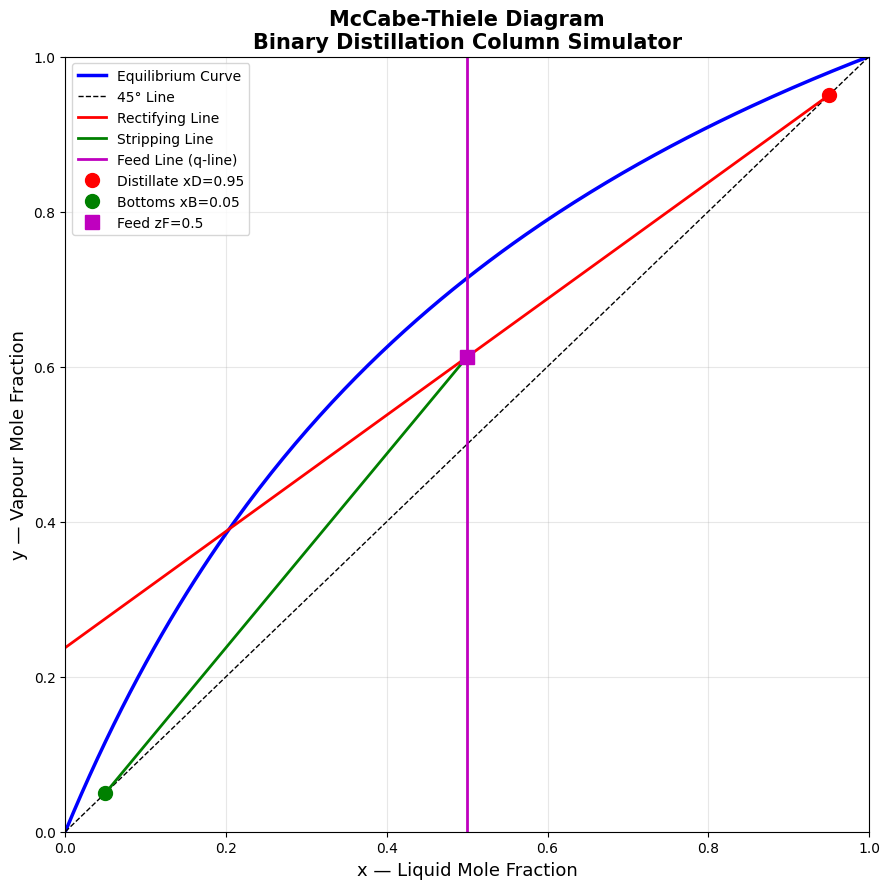

   DISTILLATION COLUMN SIMULATION RESULTS
  Feed Composition (zF):      0.5
  Distillate Purity (xD):     0.95
  Bottoms Composition (xB):   0.05
  Reflux Ratio (R):           3.0
  Relative Volatility (α):    2.5
  Feed Condition (q):         1.0


In [5]:
# ═══════════════════════════════════════════════
# BINARY DISTILLATION COLUMN SIMULATOR
# Aarya Mengle | BITS Pilani Dubai
# Method: McCabe-Thiele
# ═══════════════════════════════════════════════

import numpy as np
import matplotlib.pyplot as plt

# ── USER INPUTS ─────────────────────────────────
alpha = 2.5    # Relative volatility (how easy to separate)
zF    = 0.50   # Feed composition (0 to 1)
xD    = 0.95   # Distillate purity we want (top product)
xB    = 0.05   # Bottoms composition (bottom product)
R     = 3.0    # Reflux ratio
q     = 1.0    # Feed condition (1 = saturated liquid)

# ── EQUILIBRIUM CURVE ───────────────────────────
x = np.linspace(0, 1, 200)
y_eq = (alpha * x) / (1 + (alpha - 1) * x)

# ── OPERATING LINES ─────────────────────────────
# Rectifying (top) section
x_rect = np.linspace(0, xD, 200)
y_rect = (R / (R + 1)) * x_rect + xD / (R + 1)

# Feed line (q-line)
if q != 1:
    x_q = np.linspace(xB, xD, 200)
    y_q = (q / (q - 1)) * x_q - zF / (q - 1)
else:
    x_q = np.array([zF, zF])
    y_q = np.array([0, 1])

# Intersection of rectifying line and q-line
if q != 1:
    x_int = ((R + 1) * zF / (q - 1) + xD) / (R + 1 + (q / (q - 1)))
else:
    x_int = zF
y_int = (R / (R + 1)) * x_int + xD / (R + 1)

# Stripping (bottom) section
x_strip = np.linspace(xB, x_int, 200)
slope_s = (y_int - xB) / (x_int - xB)
y_strip = slope_s * (x_strip - xB) + xB

# ── PLOT ────────────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 9))

ax.plot(x, y_eq,    'b-',  linewidth=2.5, label='Equilibrium Curve')
ax.plot(x, x,       'k--', linewidth=1,   label='45° Line')
ax.plot(x_rect, y_rect, 'r-', linewidth=2, label='Rectifying Line')
ax.plot(x_strip, y_strip, 'g-', linewidth=2, label='Stripping Line')
ax.plot(x_q, y_q,   'm-',  linewidth=2,   label='Feed Line (q-line)')

# Mark key points
ax.plot(xD, xD, 'ro', markersize=10, label=f'Distillate xD={xD}')
ax.plot(xB, xB, 'go', markersize=10, label=f'Bottoms xB={xB}')
ax.plot(zF, y_int, 'ms', markersize=10, label=f'Feed zF={zF}')

ax.set_xlabel('x — Liquid Mole Fraction', fontsize=13)
ax.set_ylabel('y — Vapour Mole Fraction', fontsize=13)
ax.set_title('McCabe-Thiele Diagram\nBinary Distillation Column Simulator', fontsize=15, fontweight='bold')
ax.legend(loc='upper left', fontsize=10)
ax.grid(True, alpha=0.3)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)

plt.tight_layout()
plt.show()

# ── RESULTS ─────────────────────────────────────
print("=" * 45)
print("   DISTILLATION COLUMN SIMULATION RESULTS")
print("=" * 45)
print(f"  Feed Composition (zF):      {zF}")
print(f"  Distillate Purity (xD):     {xD}")
print(f"  Bottoms Composition (xB):   {xB}")
print(f"  Reflux Ratio (R):           {R}")
print(f"  Relative Volatility (α):    {alpha}")
print(f"  Feed Condition (q):         {q}")
print("=" * 45)


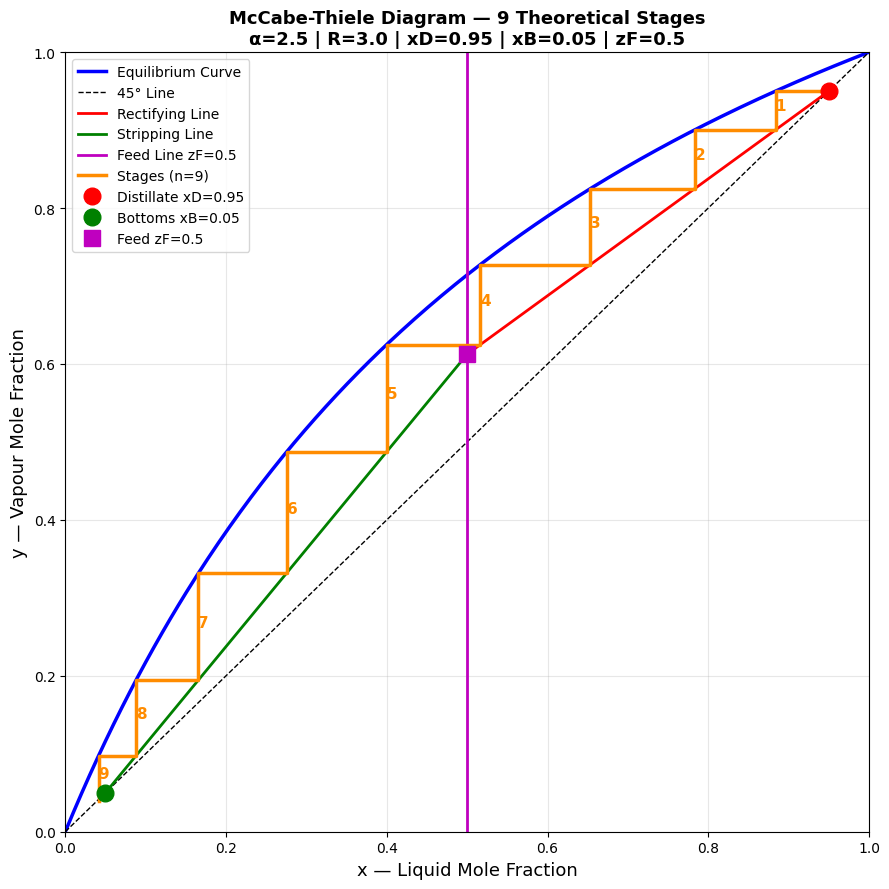

   DISTILLATION COLUMN SIMULATION RESULTS
  Theoretical Stages:      9
  Feed Composition (zF):   0.5
  Distillate Purity (xD):  0.95
  Bottoms (xB):            0.05
  Reflux Ratio (R):        3.0
  Relative Volatility (α): 2.5


In [7]:
import numpy as np
import matplotlib.pyplot as plt

# ══════════════════════════════════════════════
# BINARY DISTILLATION COLUMN SIMULATOR
# Aarya Mengle | BITS Pilani Dubai
# Method: McCabe-Thiele
# ══════════════════════════════════════════════

# ── INPUTS ─────────────────────────────────────
alpha = 2.5    # Relative volatility
zF    = 0.50   # Feed composition
xD    = 0.95   # Distillate purity
xB    = 0.05   # Bottoms composition
R     = 3.0    # Reflux ratio

# ── FUNCTIONS ──────────────────────────────────
def y_eq(x):
    return (alpha * x) / (1 + (alpha - 1) * x)

def x_from_y_eq(y):
    return y / (alpha - (alpha - 1) * y)

def y_rect(x):
    return (R / (R + 1)) * x + xD / (R + 1)

x_int = zF
y_int = y_rect(x_int)
slope_s = (y_int - xB) / (x_int - xB)

def y_strip(x):
    return slope_s * (x - xB) + xB

# ── STAGE STEPPING ─────────────────────────────
stair_x = []
stair_y = []
x_cur = xD
y_cur = xD
stage_count = 0

for _ in range(30):
    # Horizontal to equilibrium curve
    x_eq = x_from_y_eq(y_cur)
    stair_x.extend([x_cur, x_eq])
    stair_y.extend([y_cur, y_cur])

    # Vertical down to operating line
    if x_eq >= x_int:
        y_new = y_rect(x_eq)
    else:
        y_new = y_strip(x_eq)

    stair_x.extend([x_eq, x_eq])
    stair_y.extend([y_cur, y_new])

    stage_count += 1
    x_cur = x_eq
    y_cur = y_new

    if x_eq <= xB + 0.005:
        break

# ── PLOT ───────────────────────────────────────
x_arr       = np.linspace(0, 1, 300)
x_rect_arr  = np.linspace(x_int, xD, 200)
x_strip_arr = np.linspace(xB, x_int, 200)

fig, ax = plt.subplots(figsize=(9, 9))
ax.plot(x_arr, y_eq(x_arr),               'b-',  lw=2.5, label='Equilibrium Curve')
ax.plot(x_arr, x_arr,                     'k--', lw=1,   label='45° Line')
ax.plot(x_rect_arr,  y_rect(x_rect_arr),  'r-',  lw=2,   label='Rectifying Line')
ax.plot(x_strip_arr, y_strip(x_strip_arr),'g-',  lw=2,   label='Stripping Line')
ax.axvline(x=zF, color='m', lw=2, label=f'Feed Line zF={zF}')
ax.plot(stair_x, stair_y, color='darkorange', lw=2.5, label=f'Stages (n={stage_count})')

# Stage numbers
for i in range(stage_count):
    idx = i * 4
    if idx + 2 < len(stair_x):
        ax.annotate(f'{i+1}',
                    xy=(stair_x[idx+2], (stair_y[idx+2]+stair_y[idx+3])/2),
                    fontsize=11, color='darkorange', fontweight='bold')

ax.plot(xD, xD,   'ro', ms=12, zorder=5, label=f'Distillate xD={xD}')
ax.plot(xB, xB,   'go', ms=12, zorder=5, label=f'Bottoms xB={xB}')
ax.plot(zF,y_int, 'ms', ms=12, zorder=5, label=f'Feed zF={zF}')

ax.set_xlabel('x — Liquid Mole Fraction', fontsize=13)
ax.set_ylabel('y — Vapour Mole Fraction', fontsize=13)
ax.set_title(f'McCabe-Thiele Diagram — {stage_count} Theoretical Stages\n'
             f'α={alpha} | R={R} | xD={xD} | xB={xB} | zF={zF}',
             fontsize=13, fontweight='bold')
ax.legend(loc='upper left', fontsize=10)
ax.grid(True, alpha=0.3)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()

# ── RESULTS ────────────────────────────────────
print("=" * 45)
print("   DISTILLATION COLUMN SIMULATION RESULTS")
print("=" * 45)
print(f"  Theoretical Stages:      {stage_count}")
print(f"  Feed Composition (zF):   {zF}")
print(f"  Distillate Purity (xD):  {xD}")
print(f"  Bottoms (xB):            {xB}")
print(f"  Reflux Ratio (R):        {R}")
print(f"  Relative Volatility (α): {alpha}")
print("=" * 45)

In [8]:
# ══════════════════════════════════════════════
# INTERACTIVE INPUT PANEL
# Change these values and re-run to simulate
# different separation scenarios
# ══════════════════════════════════════════════

from ipywidgets import interact, FloatSlider, Layout
import ipywidgets as widgets

def run_simulation(alpha, zF, xD, xB, R):

    def y_eq(x):
        return (alpha * x) / (1 + (alpha - 1) * x)

    def x_from_y_eq(y):
        return y / (alpha - (alpha - 1) * y)

    def y_rect(x):
        return (R / (R + 1)) * x + xD / (R + 1)

    x_int = zF
    y_int = y_rect(x_int)
    slope_s = (y_int - xB) / (x_int - xB)

    def y_strip(x):
        return slope_s * (x - xB) + xB

    # Stage stepping
    stair_x, stair_y = [], []
    x_cur, y_cur = xD, xD
    stage_count = 0

    for _ in range(50):
        x_eq = x_from_y_eq(y_cur)
        stair_x.extend([x_cur, x_eq])
        stair_y.extend([y_cur, y_cur])
        y_new = y_rect(x_eq) if x_eq >= x_int else y_strip(x_eq)
        stair_x.extend([x_eq, x_eq])
        stair_y.extend([y_cur, y_new])
        stage_count += 1
        x_cur, y_cur = x_eq, y_new
        if x_eq <= xB + 0.005:
            break

    # Plot
    x_arr = np.linspace(0, 1, 300)
    fig, ax = plt.subplots(figsize=(9, 9))
    ax.plot(x_arr, y_eq(x_arr), 'b-', lw=2.5, label='Equilibrium Curve')
    ax.plot(x_arr, x_arr, 'k--', lw=1, label='45° Line')
    ax.plot(np.linspace(x_int,xD,200), y_rect(np.linspace(x_int,xD,200)), 'r-', lw=2, label='Rectifying Line')
    ax.plot(np.linspace(xB,x_int,200), y_strip(np.linspace(xB,x_int,200)), 'g-', lw=2, label='Stripping Line')
    ax.axvline(x=zF, color='m', lw=2, label=f'Feed Line')
    ax.plot(stair_x, stair_y, color='darkorange', lw=2.5, label=f'Stages (n={stage_count})')

    for i in range(stage_count):
        idx = i * 4
        if idx + 2 < len(stair_x):
            ax.annotate(f'{i+1}', xy=(stair_x[idx+2], (stair_y[idx+2]+stair_y[idx+3])/2),
                       fontsize=10, color='darkorange', fontweight='bold')

    ax.plot(xD, xD, 'ro', ms=12, zorder=5, label=f'Distillate xD={xD}')
    ax.plot(xB, xB, 'go', ms=12, zorder=5, label=f'Bottoms xB={xB}')
    ax.plot(zF, y_int, 'ms', ms=12, zorder=5, label=f'Feed zF={zF}')
    ax.set_xlabel('x — Liquid Mole Fraction', fontsize=13)
    ax.set_ylabel('y — Vapour Mole Fraction', fontsize=13)
    ax.set_title(f'McCabe-Thiele Diagram — {stage_count} Theoretical Stages\n'
                 f'α={alpha} | R={R} | xD={xD} | xB={xB} | zF={zF}',
                 fontsize=13, fontweight='bold')
    ax.legend(loc='upper left', fontsize=10)
    ax.grid(True, alpha=0.3)
    ax.set_xlim(0,1); ax.set_ylim(0,1)
    plt.tight_layout()
    plt.show()

    print(f"\n{'='*45}")
    print(f"  THEORETICAL STAGES: {stage_count}")
    print(f"  α={alpha} | R={R} | xD={xD} | xB={xB} | zF={zF}")
    print(f"{'='*45}")

# ── SLIDERS ────────────────────────────────────
interact(run_simulation,
    alpha = FloatSlider(min=1.1, max=5.0, step=0.1, value=2.5, description='Volatility α'),
    zF    = FloatSlider(min=0.1, max=0.9, step=0.05, value=0.5, description='Feed zF'),
    xD    = FloatSlider(min=0.7, max=0.99, step=0.01, value=0.95, description='Distillate xD'),
    xB    = FloatSlider(min=0.01, max=0.2, step=0.01, value=0.05, description='Bottoms xB'),
    R     = FloatSlider(min=1.0, max=8.0, step=0.5, value=3.0, description='Reflux R'),
)

interactive(children=(FloatSlider(value=2.5, description='Volatility α', max=5.0, min=1.1), FloatSlider(value=…

<function __main__.run_simulation(alpha, zF, xD, xB, R)>